<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup, fixture and runtime](README.md)

# 01 · Count a conversation without counting its thread parents twice

Channel history and thread reads answer different questions. A thread read includes its parent, so appending it to history can count the same message twice. A parent's `reply_count` also describes the returned parent metadata, not how many replies fall inside our chosen time window.

We will reconcile those populations, retain an observed empty channel separately from an unobserved one, and measure only the first identified human reply actually seen before the cutoff. Then we will widen the window while keeping every source response fixed.

**Entirely synthetic local workspace.** Every channel, identity, timestamp and message is authored for this example. The real unchanged worker reads a local API fixture that pages at three items and returns one retryable 429 per request URL. No Slack workspace is contacted, no real token is read and no message is posted. This is not a team-performance or response-time benchmark.

## Choose a half-open observation window

`WINDOW_HOURS` is an integer from **1 to 3**, default **1**; the experiment uses **2**. Analysis starts at **2026-01-01 00:00:00 UTC**, inclusive, and ends at start plus this many hours, **exclusive**. The fixture contains messages exactly on every hour boundary so endpoint handling is visible.

The fixed history fetch interval is **[00:00, 03:00] UTC**, closed at both ends. The worker sends Slack `inclusive=true`. We then select the half-open analytical interval locally. Four fixed thread reads fetch their whole synthetic threads because this worker's `replies()` has no time-bound arguments. They are finite fixture reads, not a claim that real thread retrieval is bounded by the history window. Restart Kernel → Run All after editing.

In [1]:
WINDOW_HOURS = 1  # Half-open analytical hours from 2026-01-01 00:00 UTC; experiment: 2

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from fixture_api import FixtureAPI

assert type(WINDOW_HOURS) is int and 1 <= WINDOW_HOURS <= 3
api = FixtureAPI(Path("fixtures"), Path("artifacts"))
FIXTURE_API_URL = api.url
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Synthetic local Slack fixture · 2026-01-01 UTC · real worker · no workspace contacted or messages sent",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.93))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-slack--slack-worker/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-slack--slack-worker/notebooks/pyproject.toml.

## Connect to immutable source with a tested protocol runtime

The visible Bun/Git launcher fetches one remote commit. Its notebook-only frozen runtime uses published SDK **0.50.0** because the source's locked **0.49.1** speaks protocol 3.2, while Haybarn 2.0.0rc11 expects 3.3. Source files and the root lock are unchanged. The launcher verifies the commit, hashes the runtime manifest/lock, serializes cache installation, and sends setup diagnostics to stderr. See the README for the source-suite evidence under this exact override.

The literal token below is the non-secret synthetic token accepted only by the fixture. The endpoint is the owned loopback fixture. A channel ID avoids name-resolution requests. Materialize each read once before displaying or joining it.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'slack' (
 TYPE vgi,
 LOCATION 'bun run github_worker.ts Query-farm/vgi-slack 65b5c84678ba47f96fd759242be89c199b3d1ee5 src/worker.ts',
 token 'notebook-fixture-only', api_url '{{FIXTURE_API_URL}}'
);
CREATE TABLE identity AS SELECT * FROM slack.auth_info();
CREATE TABLE channels AS SELECT * FROM slack.channels(exclude_archived := false);
CREATE TABLE directory AS SELECT * FROM slack.users(include_deleted := true);
CREATE TABLE history AS
SELECT * FROM slack.messages('C0HELP',oldest := TIMESTAMPTZ '2026-01-01 00:00:00+00',latest := TIMESTAMPTZ '2026-01-01 03:00:00+00')
UNION ALL
SELECT * FROM slack.messages('C0EMPTY',oldest := TIMESTAMPTZ '2026-01-01 00:00:00+00',latest := TIMESTAMPTZ '2026-01-01 03:00:00+00');
CREATE TABLE thread_rows AS
SELECT 'T1' AS thread_label,* FROM slack.replies('C0HELP','1767226200.000100')
UNION ALL SELECT 'T2',* FROM slack.replies('C0HELP','1767228600.000100')
UNION ALL SELECT 'T3',* FROM slack.replies('C0HELP','1767231000.000100')
UNION ALL SELECT 'T4',* FROM slack.replies('C0HELP','1767233400.000100');
CREATE TABLE bounds AS SELECT TIMESTAMPTZ '2026-01-01 00:00:00+00' AS start_utc,
 TIMESTAMPTZ '2026-01-01 00:00:00+00' + INTERVAL '{{WINDOW_HOURS}} hours' AS end_utc;
SELECT team,user FROM identity;

,team,user
0,Synthetic notebook workspace,Fixture Bot


In [4]:
audit = json.loads(Path("artifacts/request-audit.json").read_text())
assert all(r["method"] == "GET" and r["status"] in {200, 429} for r in audit)
requests = pd.DataFrame([{"endpoint": r["endpoint"], "status": r["status"]} for r in audit])
display(requests.groupby(["endpoint", "status"]).size().rename("requests").reset_index())
for r in audit:
    key = (r["endpoint"], json.dumps(r["query"], sort_keys=True))
    related = [x for x in audit if (x["endpoint"], json.dumps(x["query"], sort_keys=True)) == key]
    assert sorted(x["status"] for x in related) == [200, 429]
assert con.execute("SELECT count(*)=count(DISTINCT (channel_id,ts)) FROM history").fetchone()[0]
assert con.execute(
    "SELECT count(*)=count(DISTINCT (thread_label,channel_id,ts)) FROM thread_rows"
).fetchone()[0]
assert con.execute(
    "SELECT bool_and(epoch_us(posted_at)=split_part(ts,'.',1)::BIGINT*1000000+rpad(split_part(ts,'.',2),6,'0')::BIGINT) FROM (SELECT * FROM history UNION ALL SELECT * EXCLUDE(thread_label) FROM thread_rows)"
).fetchone()[0]
source_rows = con.execute(
    "SELECT 'history' AS source,* FROM history UNION ALL SELECT thread_label,* EXCLUDE(thread_label) FROM thread_rows ORDER BY source,channel_id,ts"
).df()
fingerprint = hashlib.sha256(source_rows.to_json(orient="records", date_format="iso").encode()).hexdigest()
prose(
    f"The unchanged worker followed **{sum(r['status'] == 200 for r in audit)} successful pages** and handled **{sum(r['status'] == 429 for r in audit)} deliberate rate limits**. Every successful page has exactly one preceding 429; no POST occurred. Message IDs round-trip exactly to timestamp microseconds. Fixed source fingerprint: `{fingerprint}`. Fixture SHA256: `{api.fixture_hash}`."
)

,endpoint,status,requests
0,auth.test,200,1
1,auth.test,429,1
2,conversations.history,200,5
3,conversations.history,429,5
4,conversations.list,200,1
5,conversations.list,429,1
6,conversations.replies,200,5
7,conversations.replies,429,5
8,users.list,200,2
9,users.list,429,2


The unchanged worker followed **14 successful pages** and handled **14 deliberate rate limits**. Every successful page has exactly one preceding 429; no POST occurred. Message IDs round-trip exactly to timestamp microseconds. Fixed source fingerprint: `f594b699726bc66f8dd05c6ff4b0a2b8aab331ccfec5de0aef108bcbc812ae06`. Fixture SHA256: `1bfe109f4d06673c0294e21ce2cd135167d21e5ed094fa0f381f4fed6011fe54`.

## Reconcile the two read paths before counting

Slack returns a thread's parent as well as replies; a thread with no replies still returns its parent. The history call's explicit inclusive bounds are distinct from our half-open local selection. These endpoint semantics are documented for [history](https://docs.slack.dev/reference/methods/conversations.history/) and [replies](https://docs.slack.dev/reference/methods/conversations.replies/).

Use **`(channel_id, ts)`** as the event key. Keep history's version when the same event arrives through both paths; the fixture versions agree, while a real live comparison could observe edits between reads. Directory joins are left joins: an absent user stays unresolved, and deactivated users remain available because we requested them. Bot and system events are separate from identified human messages.

In [5]:
%%sql
CREATE TABLE combined AS
SELECT 'history' AS read_path,* FROM history
UNION ALL SELECT 'thread',* EXCLUDE(thread_label) FROM thread_rows;
CREATE TABLE unique_events AS
SELECT * EXCLUDE(read_path,choice) FROM (
 SELECT *,row_number() OVER(PARTITION BY channel_id,ts ORDER BY CASE WHEN read_path='history' THEN 0 ELSE 1 END) AS choice
 FROM combined
) WHERE choice=1;
CREATE TABLE classified AS
SELECT e.*,u.real_name,u.deleted AS author_deactivated,
 CASE WHEN e.type<>'message' OR e.subtype='channel_join' THEN 'system'
      WHEN e.bot_id IS NOT NULL OR u.is_bot THEN 'bot'
      WHEN u.id IS NULL OR e.user_id IS NULL THEN 'unresolved'
      ELSE 'identified human' END AS event_kind
FROM unique_events e LEFT JOIN directory u ON e.user_id=u.id;
CREATE TABLE selected AS SELECT c.* FROM classified c CROSS JOIN bounds b
WHERE c.posted_at>=b.start_utc AND c.posted_at<b.end_utc;

,Count


In [6]:
%%sql populations <<
SELECT 'History only' AS population,count(*) AS rows FROM history CROSS JOIN bounds WHERE posted_at>=start_utc AND posted_at<end_utc
UNION ALL SELECT 'Naive history + threads',count(*) FROM combined CROSS JOIN bounds WHERE posted_at>=start_utc AND posted_at<end_utc
UNION ALL SELECT 'Unique conversation events',count(*) FROM selected;

In [7]:
%%sql channel_status <<
SELECT c.id,c.name,c.is_member,
 CASE WHEN c.id IN ('C0HELP','C0EMPTY') THEN 'observed in fixed fetch' ELSE 'not observed' END AS coverage,
 CASE WHEN c.id IN ('C0HELP','C0EMPTY') THEN count(s.ts) ELSE NULL END AS selected_events
FROM channels c LEFT JOIN selected s ON c.id=s.channel_id GROUP BY c.id,c.name,c.is_member ORDER BY c.id;

,population,rows
0,History only,4
1,Naive history + threads,8
2,Unique conversation events,6


,id,name,is_member,coverage,selected_events
0,C0EMPTY,empty,True,observed in fixed fetch,0
1,C0HELP,help,True,observed in fixed fetch,6
2,C0OTHER,unobserved,False,not observed,<NA>


,event_kind,events
0,bot,1
1,identified human,4
2,unresolved,1


In **[00:00, 01:00) UTC**, history alone has **4 events**. Appending thread rows naively gives **8**, including **2 repeated parents**. Deduplication retains **6 unique events**. The observed empty channel is **zero**; the unobserved channel remains **NULL**. Neither a missing directory identity nor a deactivated account makes an event disappear.

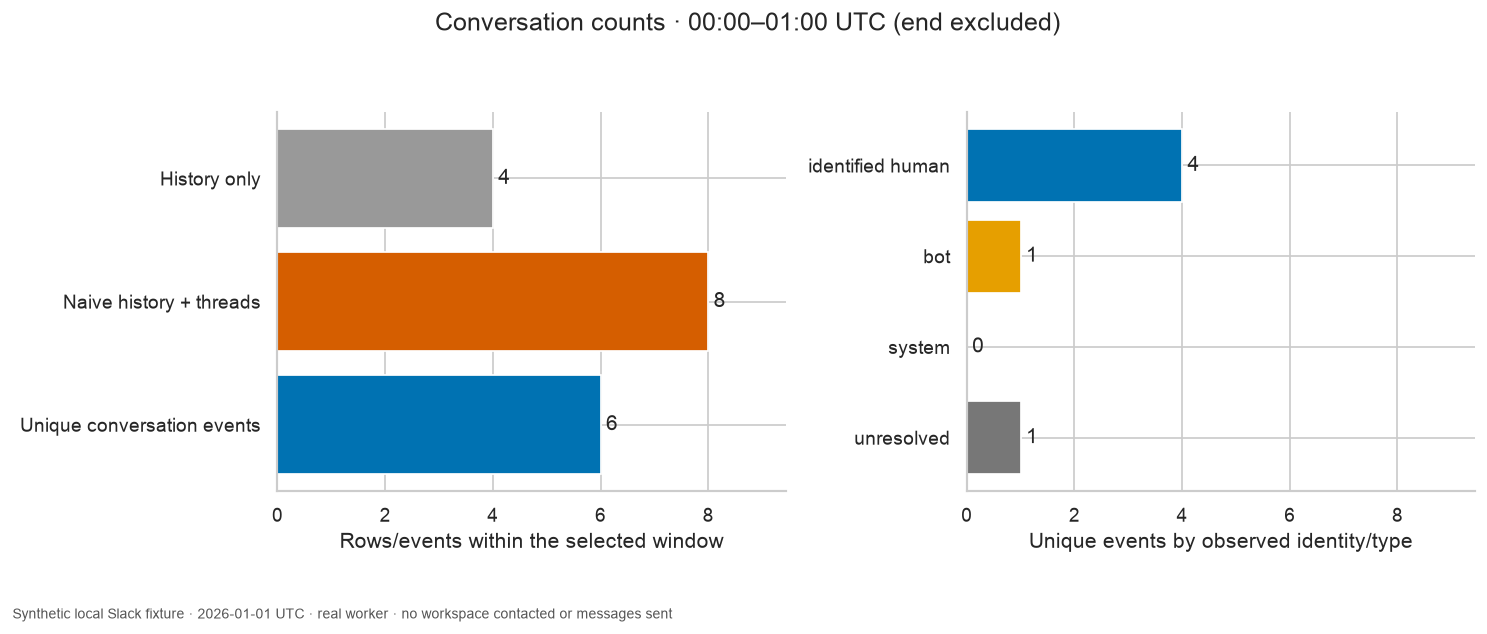

In [8]:
display(populations)
display(channel_status)
kinds = con.execute(
    "SELECT event_kind,count(*) AS events FROM selected GROUP BY event_kind ORDER BY event_kind"
).df()
display(kinds)
counts = populations.set_index("population")["rows"]
assert counts["Naive history + threads"] >= counts["Unique conversation events"] >= counts["History only"]
assert con.execute("SELECT count(*)=count(DISTINCT (channel_id,ts)) FROM selected").fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM selected CROSS JOIN bounds WHERE posted_at<start_utc OR posted_at>=end_utc"
    ).fetchone()[0]
    == 0
)
assert con.execute("SELECT count(*) FROM history CROSS JOIN bounds WHERE posted_at=end_utc").fetchone()[0] > 0
assert con.execute("SELECT count(*) FROM selected WHERE ts='1767225600.000000'").fetchone()[0] == 1
assert (
    con.execute(
        "SELECT count(*) FROM thread_rows r JOIN history h USING(channel_id,ts) WHERE r.text IS DISTINCT FROM h.text OR r.reply_count IS DISTINCT FROM h.reply_count"
    ).fetchone()[0]
    == 0
)
assert con.execute("SELECT count(*) FROM selected").fetchone()[0] == kinds.events.sum()
assert channel_status.loc[channel_status.id == "C0EMPTY", "selected_events"].iloc[0] == 0
assert pd.isna(channel_status.loc[channel_status.id == "C0OTHER", "selected_events"].iloc[0])
prose(
    f"In **[00:00, {WINDOW_HOURS:02d}:00) UTC**, history alone has **{counts['History only']} events**. Appending thread rows naively gives **{counts['Naive history + threads']}**, including **{counts['Naive history + threads'] - counts['Unique conversation events']} repeated parents**. Deduplication retains **{counts['Unique conversation events']} unique events**. The observed empty channel is **zero**; the unobserved channel remains **NULL**. Neither a missing directory identity nor a deactivated account makes an event disappear."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(populations.population, populations.rows, color=["#999999", "#d55e00", "#0072b2"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Rows/events within the selected window")
for i, row in enumerate(populations.itertuples()):
    axes[0].text(row.rows + 0.1, i, str(row.rows), va="center")
axes[0].set_xlim(0, max(populations.rows) * 1.18)
kind_order = ["identified human", "bot", "system", "unresolved"]
palette = {"identified human": "#0072b2", "bot": "#e69f00", "system": "#009e73", "unresolved": "#777777"}
v = kinds.set_index("event_kind").events.reindex(kind_order, fill_value=0)
axes[1].barh(v.index, v.values, color=[palette[k] for k in v.index])
axes[1].invert_yaxis()
axes[1].set_xlabel("Unique events by observed identity/type")
for i, value in enumerate(v.values):
    axes[1].text(value + 0.1, i, str(value), va="center")
axes[1].set_xlim(axes[0].get_xlim())
fig.suptitle(f"Conversation counts · 00:00–{WINDOW_HOURS:02d}:00 UTC (end excluded)")
finish(fig)

## A reply count is not an in-window response measure

Select the cohort of thread parents posted inside the analytical window. For each, exclude the repeated parent and count observed replies before the cutoff. Measure first **identified human** reply time only when that reply is observed. A bot reply is shown separately; an unknown directory identity is not assumed human.

A NULL first-reply delay means **no identified human reply observed before this cutoff**, not zero minutes and not “never answered.” The current `reply_count` may include replies outside the window. This parent cohort also omits older threads with replies in the window; conversation-event counts above include every hydrated event in the window, so the populations differ intentionally.

In [9]:
%%sql threads <<
WITH parents AS (
 SELECT h.* FROM history h CROSS JOIN bounds b
 WHERE h.reply_count IS NOT NULL AND h.posted_at>=b.start_utc AND h.posted_at<b.end_utc
), responses AS (
 SELECT p.ts AS parent_ts,count(r.ts) AS observed_replies,
 count(r.ts) FILTER(WHERE c.event_kind='identified human') AS identified_human_replies,
 count(r.ts) FILTER(WHERE c.event_kind='bot') AS bot_replies,
 min(r.posted_at) FILTER(WHERE c.event_kind='identified human') AS first_human_reply
 FROM parents p CROSS JOIN bounds b
 LEFT JOIN thread_rows r ON r.channel_id=p.channel_id AND r.thread_ts=p.ts AND r.ts<>p.ts AND r.posted_at<b.end_utc
 LEFT JOIN classified c ON c.channel_id=r.channel_id AND c.ts=r.ts
 GROUP BY p.ts
)
SELECT p.ts AS parent_ts,p.posted_at AT TIME ZONE 'UTC' AS parent_utc,p.reply_count AS reported_total_replies,
 r.observed_replies,r.identified_human_replies,r.bot_replies,
 epoch(r.first_human_reply-p.posted_at)/60 AS first_observed_human_reply_minutes,
 epoch(b.end_utc-p.posted_at)/60 AS minutes_until_cutoff,
 CASE WHEN r.first_human_reply IS NULL THEN 'none observed before cutoff' ELSE 'observed before cutoff' END AS observation_status
FROM parents p JOIN responses r ON p.ts=r.parent_ts CROSS JOIN bounds b ORDER BY p.ts;

,parent_ts,parent_utc,reported_total_replies,observed_replies,identified_human_replies,bot_replies,first_observed_human_reply_minutes,minutes_until_cutoff,observation_status
0,1767226200.000100,2026-01-01 00:10:00.000100,3,2,1,1,5.0,49.999998,observed before cutoff
1,1767228600.000100,2026-01-01 00:50:00.000100,2,0,0,0,NaN,9.999998,none observed before cutoff


The selected parent cohort has **2 threads**, with **2 observed replies** before the cutoff. **1** have an identified human reply; **1** do not yet have one in this window. Their missing delays stay NULL. Parent metadata reports **5 total replies**, which includes later fixture activity and must not replace the in-window count.

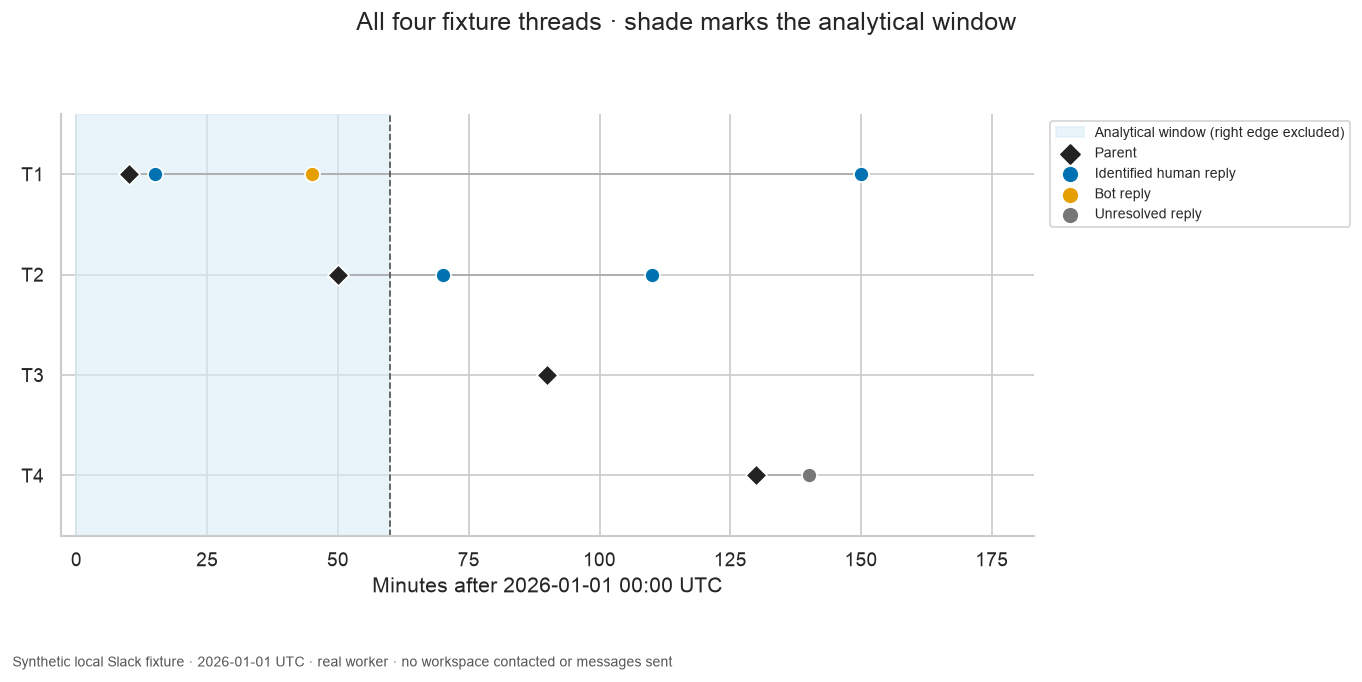

8909

In [10]:
display(threads)
assert (threads.observed_replies <= threads.reported_total_replies).all()
assert (threads.identified_human_replies + threads.bot_replies <= threads.observed_replies).all()
known = threads.first_observed_human_reply_minutes.dropna()
assert (known >= 0).all()
assert (
    threads.first_observed_human_reply_minutes.dropna() < threads.loc[known.index, "minutes_until_cutoff"]
).all()
assert threads.first_observed_human_reply_minutes.isna().equals(threads.identified_human_replies.eq(0))
all_thread_checks = con.execute(
    "SELECT h.ts,h.reply_count,count(r.ts) FILTER(WHERE r.ts<>h.ts) AS actual FROM history h JOIN thread_rows r ON h.ts=r.thread_ts AND h.channel_id=r.channel_id WHERE h.reply_count IS NOT NULL GROUP BY h.ts,h.reply_count"
).df()
assert (all_thread_checks.reply_count == all_thread_checks.actual).all()
prose(
    f"The selected parent cohort has **{len(threads)} threads**, with **{int(threads.observed_replies.sum())} observed replies** before the cutoff. **{len(known)}** have an identified human reply; **{int(threads.first_observed_human_reply_minutes.isna().sum())}** do not yet have one in this window. Their missing delays stay NULL. Parent metadata reports **{int(threads.reported_total_replies.sum())} total replies**, which includes later fixture activity and must not replace the in-window count."
)
timeline = con.execute(
    "SELECT r.thread_label,r.ts,r.thread_ts,epoch(r.posted_at-TIMESTAMPTZ '2026-01-01 00:00:00+00')/60 AS minute,c.event_kind FROM thread_rows r JOIN classified c USING(channel_id,ts) ORDER BY r.thread_label,r.ts"
).df()
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.axvspan(0, WINDOW_HOURS * 60, color="#d9edf7", alpha=0.6, label="Analytical window (right edge excluded)")
for i, (_label, g) in enumerate(timeline.groupby("thread_label")):
    ax.plot([g.minute.min(), g.minute.max()], [i, i], color="#aaaaaa", lw=1, zorder=1)
    for r in g.itertuples():
        parent = r.ts == r.thread_ts
        ax.scatter(
            r.minute,
            i,
            marker="D" if parent else "o",
            s=75,
            color="#222222" if parent else palette[r.event_kind],
            edgecolors="white",
            zorder=3,
        )
ax.axvline(WINDOW_HOURS * 60, color="#555555", ls="--", lw=1)
for name, marker, color in [
    ("Parent", "D", "#222222"),
    ("Identified human reply", "o", palette["identified human"]),
    ("Bot reply", "o", palette["bot"]),
    ("Unresolved reply", "o", palette["unresolved"]),
]:
    ax.scatter([], [], marker=marker, color=color, s=60, label=name)
ax.set(
    yticks=range(4),
    yticklabels=["T1", "T2", "T3", "T4"],
    xlabel="Minutes after 2026-01-01 00:00 UTC",
    xlim=(-3, 183),
    ylim=(-0.6, 3.6),
)
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle("All four fixture threads · shade marks the analytical window")
finish(fig)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "window_hours": WINDOW_HOURS,
            "fixture_sha256": api.fixture_hash,
            "source_fingerprint": fingerprint,
            "request_audit": audit,
            "populations": populations.to_dict(orient="records"),
            "channel_status": channel_status.to_dict(orient="records"),
            "event_kinds": kinds.to_dict(orient="records"),
            "threads": json.loads(threads.to_json(orient="records", date_format="iso")),
        },
        indent=2,
    )
)

## Experiment: observe one more hour

Change only `WINDOW_HOURS` from **1 to 2**. Predict additional unique events and a newly observed human response for T2; the 01:00 boundary event enters while the 02:00 boundary stays excluded. The parent cohort also grows, so the count of threads without an observed human reply need not fall.

Compare the three event populations, identity/type table, parent-cohort response table and shaded timeline. The fixture hash, fully fetched source fingerprint, complete thread timeline and paginated request audit must stay unchanged. Restore **1** afterwards.

This fixture isolates accounting and observation-window choices. It does not establish workspace coverage, unseen/deleted messages, individual effort, service quality or a statistical response-time distribution. Real access rights, retention, thread visibility and changes between API reads require separate consideration.

In [11]:
con.close()
api.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)